# 03 - Temporal Analysis

## Objetivo 

Esta etapa tem como objetivo construir e analisar as séries temporais dos dados, focando principalmente nos faturamentos. Para realizar uma análise completa, será investigado:

- Série temporal do número de vendas realizadas por ano -> Predição de demanda vale a pena neste projeto?
- Série temporal do faturamento anual por grupo
- Série temporal do faturamento mensal total
- => Qual destes é melhor para a modelagem de predição?

Ao final desta etapa será possível compreender a melhor estratégia e abordagem para a criação dos modelos de predição. Portanto, queremos:

- Definir a variável *target* do modelo;
- Descobrir possíveis inconsistências na série temporal de faturamento;
- Descobrir a existência de Tendência e Sazonalidade nos dados, seja aditiva ou multiplicativa.

In [1]:
from pathlib import Path
import pandas as pd

# Caminho do projeto
PROJECT_ROOT = Path.cwd().parent # cwd: current working directory
DATA_PATH = PROJECT_ROOT / "data" / "interm"

# Carregamento dos dados
csv_file = DATA_PATH / "data_2.csv"
banco = pd.read_csv(csv_file)

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

# Parâmetros de estilo do Gráfico baseado no manual do MBA
plt.rcParams.update({

    # Fonte
    "font.family": "Arial",
    "font.size": 11,

    # Fundo
    "figure.facecolor": "white",
    "axes.facecolor": "white",

    # Sem grade
    "axes.grid": False,

    # Sem título
    "axes.titlesize": 0,

    # Eixos
    "axes.edgecolor": "black",
    "axes.linewidth": 1.5,

    # Cor dos textos
    "axes.labelcolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",

    # Tamanho dos títulos dos eixos
    "axes.labelsize": 11

})

In [3]:
def plot_with_style(data,
                    kind='line',            # 'line' or 'bar'
                    x_label='', y_label='',
                    title='',
                    xticks=None,            # lista de posições (datas ou valores)
                    xtlabels=None,          # lista de labels para xticks
                    rotate_xticks=0,
                    figsize=(12,6),
                    marker='o',
                    linewidth=2):
    """Plota gráfico com estilo personalizado. Aceita pd.Series (index pode ser datetime) ou pd.DataFrame."""
    fig, ax = plt.subplots(figsize=figsize)

    if isinstance(data, pd.Series):
        if kind == 'line':
            ax.plot(data.index, data.values, marker=marker, linewidth=linewidth)
        else:
            ax.bar(data.index, data.values, color='C0', edgecolor='black', linewidth=0.8)

    elif isinstance(data, pd.DataFrame):
        if kind == 'line':
            data.plot(ax=ax, marker=marker, linewidth=linewidth)
        else:
            data.plot(kind='bar', ax=ax)

    else:
        raise ValueError('data deve ser pd.Series ou pd.DataFrame')

    # rótulos e título
    ax.set_xlabel(x_label, fontsize=11, fontname='Arial')
    ax.set_ylabel(y_label, fontsize=11, fontname='Arial')
    ax.set_title(title)

    ax.grid(False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.spines['left'].set_color('black')
    ax.spines['bottom'].set_color('black')
    ax.legend(title=None, frameon=False)

    if xticks is not None:
        ax.set_xticks(xticks)
    if xtlabels is not None:
        ax.set_xticklabels(xtlabels)
    if rotate_xticks:
        plt.setp(ax.get_xticklabels(), rotation=rotate_xticks, ha='right')

    plt.tight_layout()
    plt.show()

# --- Funções utilitárias para construir séries temporais reutilizáveis ---
def build_monthly_counts(df, start='2017-01-01', end='2025-08-31'):
    """Retorna pd.DataFrame (index datetime início de mês) com coluna 'qtd_vendas' contínua entre start..end."""
    monthly = (
        df.groupby(['ano', 'mes'])
        .size()
        .reset_index(name='qtd_vendas')
    )
    monthly['date'] = pd.to_datetime(dict(year=monthly['ano'], month=monthly['mes'], day=1))
    monthly = monthly.sort_values('date').set_index('date')[['qtd_vendas']]
    idx = pd.date_range(start=start, end=end, freq='MS')
    monthly = monthly.reindex(idx, fill_value=0)
    monthly.index.name = 'date'
    return monthly

def build_annual_counts(df, start_year=2017, end_year=2025):
    """Retorna pd.Series index anos com contagem de vendas por ano (preenche anos faltantes com 0)."""
    s = df.groupby(df['data_venda'].dt.year).size()
    years = list(range(start_year, end_year + 1))
    s = s.reindex(years, fill_value=0)
    s.index = s.index.astype(int)
    return s

def build_annual_faturamento_groups(df, groups, start_year=2017, end_year=2025):
    """Retorna pd.Series index anos com soma de 'valor_total' filtrada por grupos."""
    df_f = df[df['grupo'].isin(groups)].copy()
    s = df_f.groupby(df_f['data_venda'].dt.year)['valor_total'].sum()
    years = list(range(start_year, end_year + 1))
    s = s.reindex(years, fill_value=0)
    s.index = s.index.astype(int)
    return s

def build_monthly_faturamento_total(df, start='2017-01-01', end='2025-08-01'):
    """Retorna pd.DataFrame (index datetime início de mês) com coluna 'valor_total' somada por mês contínuo."""
    # se colunas 'ano' e 'mes' existirem, use-as; caso contrário extraia de data_venda
    if 'ano' in df.columns and 'mes' in df.columns:
        tmp = (
            df.groupby(['ano', 'mes'])['valor_total']
            .sum()
            .reset_index()
        )
        tmp['date'] = pd.to_datetime(dict(year=tmp['ano'], month=tmp['mes'], day=1))
    else:
        tmp = (
            df.groupby([df['data_venda'].dt.year, df['data_venda'].dt.month])['valor_total']
            .sum()
            .reset_index(name='valor_total')
        )
        tmp.columns = ['ano', 'mes', 'valor_total']
        tmp['date'] = pd.to_datetime(dict(year=tmp['ano'], month=tmp['mes'], day=1))
    monthly = tmp.sort_values('date').set_index('date')[['valor_total']]
    idx = pd.date_range(start=start, end=end, freq='MS')
    monthly = monthly.reindex(idx, fill_value=0)
    monthly.index.name = 'date'
    return monthly

def build_annual_faturamento_total(df, start_year=2017, end_year=2025):
    """Retorna pd.Series index anos com soma de 'valor_total' por ano (preenche anos faltantes com 0)."""
    s = df.groupby(df['data_venda'].dt.year)['valor_total'].sum()
    years = list(range(start_year, end_year + 1))
    s = s.reindex(years, fill_value=0)
    s.index = s.index.astype(int)
    return s


In [4]:
banco.head()

,id_produto,descricao,valor_unitario,quantidade,valor_total,data_venda,grupo
0,25,ANT. UHF GRANDE,50.0,1.0,50.0,2017-02-14,ANTENA
1,40,CONECTOR ANILHA RG06,1.0,1.0,1.0,2017-02-14,CABO
2,65,CONVERSOR DIGITAL BEDIN,110.0,1.0,110.0,2017-02-14,CONVERSOR
3,25,ANT. UHF GRANDE,50.0,1.0,50.0,2017-02-14,ANTENA
4,65,CONVERSOR DIGITAL BEDIN,110.0,1.0,110.0,2017-02-14,CONVERSOR


In [5]:
banco.info()

<class 'pandas.DataFrame'>
RangeIndex: 18157 entries, 0 to 18156
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id_produto      18157 non-null  int64  
 1   descricao       18157 non-null  str    
 2   valor_unitario  18157 non-null  float64
 3   quantidade      18157 non-null  float64
 4   valor_total     18157 non-null  float64
 5   data_venda      18157 non-null  str    
 6   grupo           18157 non-null  str    
dtypes: float64(3), int64(1), str(3)
memory usage: 993.1 KB


In [6]:
# Modificando a coluna de data para o formato datetime
banco['data_venda'] = pd.to_datetime(
    banco['data_venda'],
    errors='coerce' # Converte valores não convertíveis para NaT
)

In [7]:
banco['ano'] = banco['data_venda'].dt.year
banco['mes'] = banco['data_venda'].dt.month

## Número de vendas realizadas por ano

In [8]:
# Contagem do número de vendas por ano e mês
vendas_mes_ano = (
    banco.groupby(['ano', 'mes'])
    .size()
    .reset_index(name='qtd_vendas')
)
# reset_index(name='qtd_vendas') transforma a série resultante da contagem em um DataFrame, 
# onde 'qtd_vendas' é o nome da nova coluna que contém os valores da contagem (.size()).
vendas_mes_ano.head()

,ano,mes,qtd_vendas
0,2017,2,106
1,2017,3,368
2,2017,4,166
3,2017,5,231
4,2017,6,185


### Quantidade de Vendas por mês em cada ano

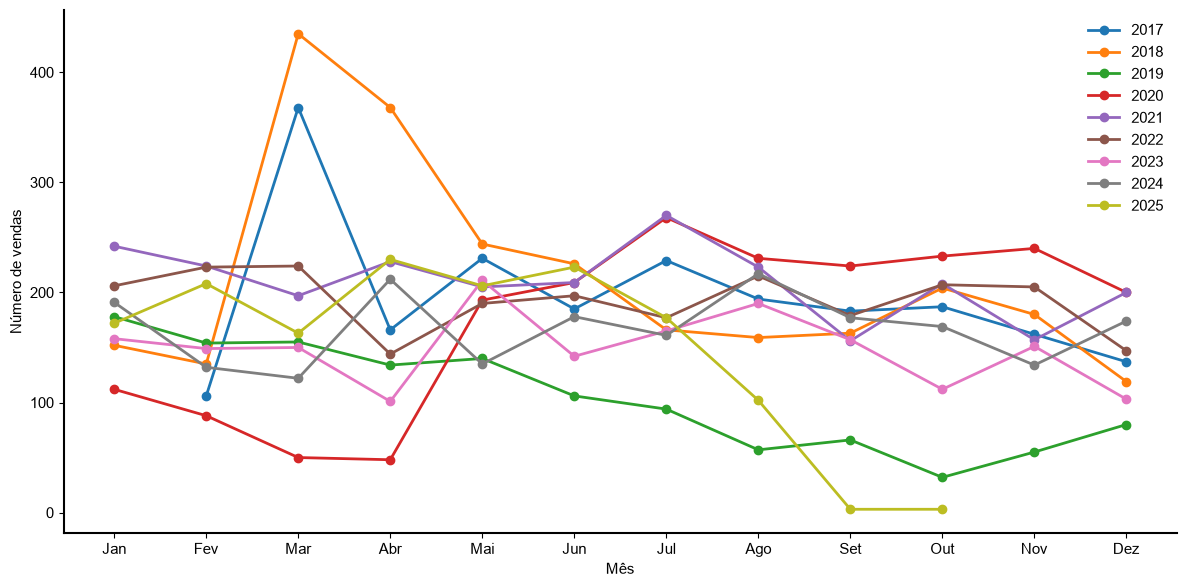

In [9]:
pivot = vendas_mes_ano.pivot(index='mes', columns='ano', values='qtd_vendas').reindex(range(1,13))
plot_with_style(pivot, kind='line',
                x_label='Mês', y_label='Número de vendas',
                xticks=range(1,13),
                xtlabels=["Jan","Fev","Mar","Abr","Mai","Jun","Jul","Ago","Set","Out","Nov","Dez"])

In [10]:
vendas_mes_ano.tail(10)

,ano,mes,qtd_vendas
95,2025,1,172
96,2025,2,208
97,2025,3,163
98,2025,4,230
99,2025,5,206
100,2025,6,223
101,2025,7,177
102,2025,8,102
103,2025,9,3
104,2025,10,3


* Análise do gráfico de quantidade de vendas por mês em cada ano:
    1) O ano de 2017 inicia apenas em fevereiro;
    2) O ano de 2025 possui uma queda drástica após o mês 08. Observando o banco de dados, nota-se um baixo número de registros de vendas nos meses 09 e 10 do ano de 2025, os quais foram comunicados pela própria empresa que foram meses de trocas de banco de dados de registros, sendo interessante removê-los do banco de dados para não criar ruídos nas séries temporais.

* Análises importantes:
    1) 2017 e 2018 possuem um alto valor de venda no mês 03, mas seguidos de alta variabilidade. 
    2) 2019 foi marcado por quedas ao longo de todo ano.
    3) 2020 despencou vendas de 01 a 04 (pandemia), mas com crescente número de vendas (possivelmente devido à instalação de TVs com suporte e itens de segurança já que tinham muitas pessoas em casa).
    4) 2021, 2022, 2023 e 2024 se mostram relativamente equilibrados e com tendência horizontal.
    5) 2025 possui uma queda brusca devido à falta de registros.

In [11]:
# Retirando os registros de setembro e outubro de 2025
banco = banco[
    ~(
        (banco['data_venda'].dt.year == 2025)
        &
        (banco['data_venda'].dt.month.isin([9, 10]))
    )
].copy()

In [12]:
banco.to_csv(
    "../data/interm/data_3.csv",
    index=False
)

A análise geral da série de demanda dos produtos mostra que há uma grande variabilidade no número de vendas por ano, entretanto, por existir registros de apenas 8 anos, a demanda anual do númmero de vendas não é interessante de ser analisada, mas abrindo caminho para a análise do número de vendas mensais ao longo dos anos.

C:\Users\Marino\AppData\Local\Temp\ipykernel_52256\572128235.py:41: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title=None, frameon=False)


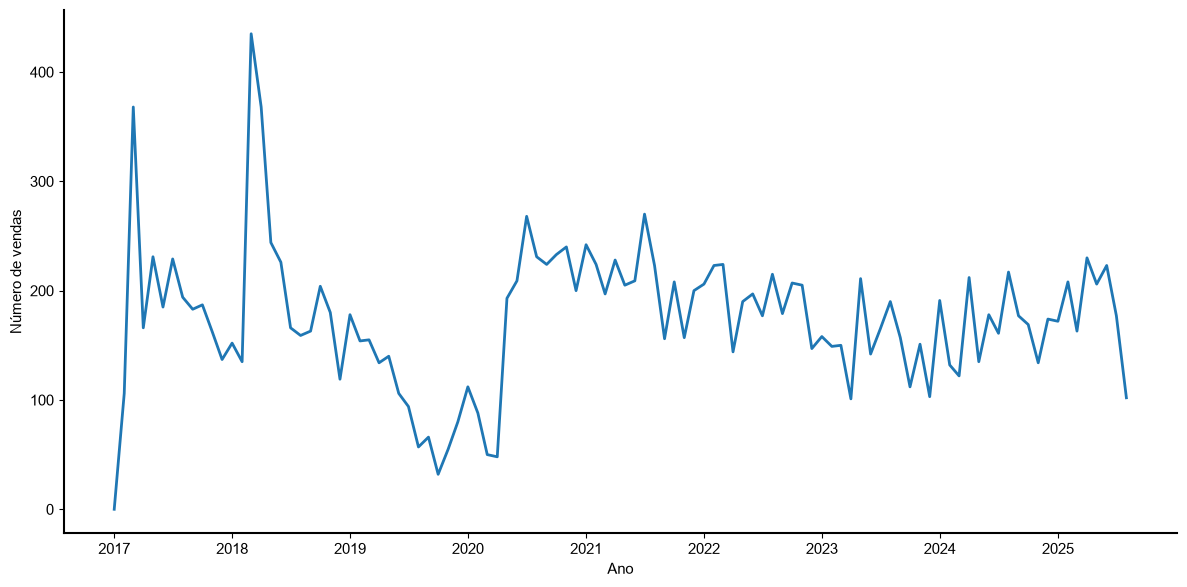

In [13]:
# 1) Agregar contagem de vendas por ano/mes (uso da função utilitária)
monthly = build_monthly_counts(banco, start='2017-01-01', end='2025-08-01')

# 2) Plot usando a função de estilo
plot_with_style(
    monthly['qtd_vendas'],
    kind='line',
    x_label='Ano',
    y_label='Número de vendas',
    title='',
    xticks=pd.date_range('2017-01-01','2025-01-01',freq='YS'),
    xtlabels=[d.year for d in pd.date_range('2017-01-01','2025-01-01',freq='YS')],
    marker=''
)

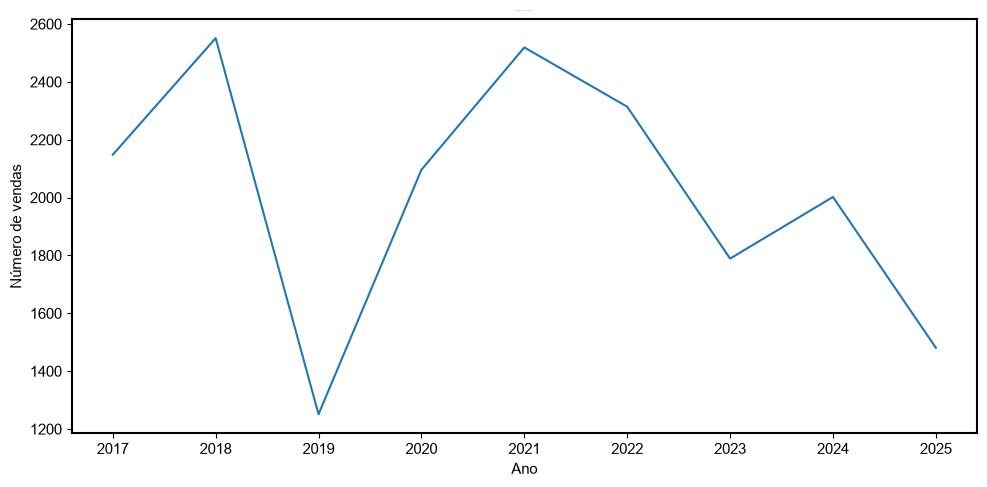

In [14]:
# Agregação: número de vendas por ano (cada linha = 1 venda)
annual = banco.set_index('data_venda').resample('YE').size().rename('num_vendas')
annual.index = annual.index.year

# Plot
plt.figure(figsize=(10,5))
sns.lineplot(x=annual.index, y=annual.values, marker='')
plt.title('Número de vendas por ano')
plt.xlabel('Ano')
plt.ylabel('Número de vendas')
plt.xticks(annual.index)
plt.grid(False)
plt.tight_layout()
plt.show()

Observando a série temporal do número de vendas mensais ao longo dos anos, pode-se perceber a existência de uma série temporal legítima. Entretanto, a predição de demanda aqui seria inútil, uma vez que são todas as vendas de todos os produtos da empresa somados. Logo, não há relevância nesta predição.

Uma ideia interessante para futuros projetos é analisar **predição de demanda por setor**, mas dependeria da quantidade de registros por grupo.

## Faturamento por ano por grupo

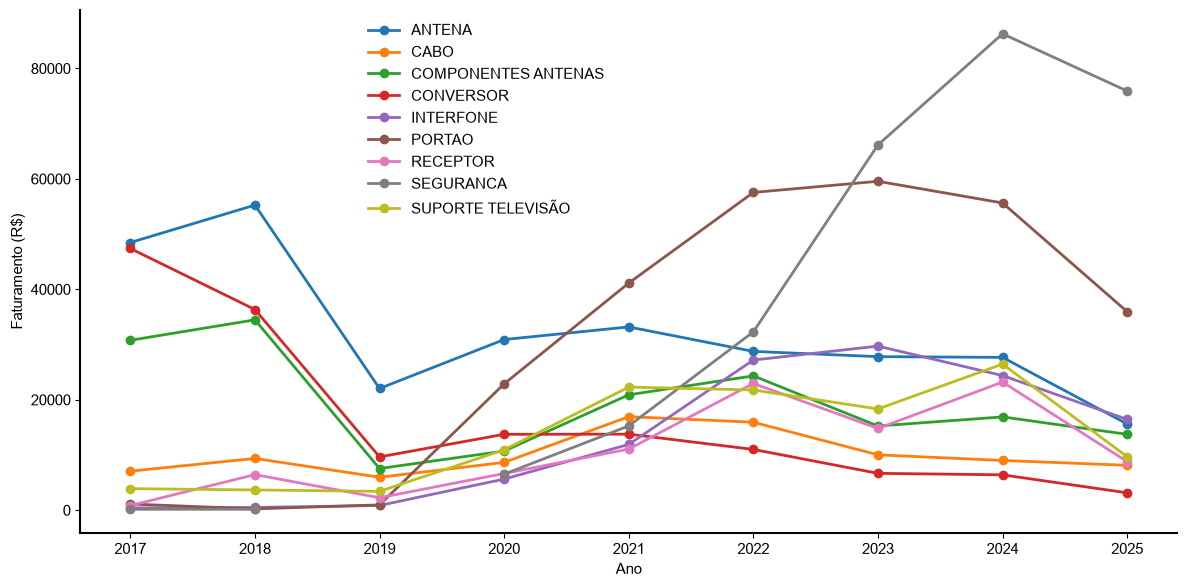

In [15]:
faturamento_grupo_ano = banco.groupby([banco['data_venda'].dt.year,'grupo'])['valor_total'].sum().reset_index()

faturamento_grupo_ano.columns = ['ano','grupo','faturamento']

pivot = faturamento_grupo_ano.pivot(
    index='ano',
    columns='grupo',
    values='faturamento'
)

fig, ax = plt.subplots(figsize=(12, 6))

pivot.plot(
    ax=ax,
    marker='o',
    linewidth=2
)

# Títulos dos eixos
ax.set_xlabel("Ano", fontsize=11, fontname="Arial")
ax.set_ylabel("Faturamento (R$)", fontsize=11, fontname="Arial")

# Remove o título
ax.set_title("")

# Remove a grade
ax.grid(False)

# Remove bordas superior e direita
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Mantém apenas os eixos principais
ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_linewidth(1.5)

ax.spines["left"].set_color("black")
ax.spines["bottom"].set_color("black")

# Legenda
ax.legend(
    title=None,
    bbox_to_anchor=(0.25, 1),
    loc="upper left",
    frameon=False
)

plt.tight_layout()
plt.show()

In [16]:
def plot_faturamento_anual(df, grupos, titulo):
    df_filtrado = df[df["grupo"].isin(grupos)].copy()

    anual = (
        df_filtrado
        .groupby([df_filtrado["data_venda"].dt.year, "grupo"])["valor_total"]
        .sum()
        .reset_index()
        .pivot(index="data_venda", columns="grupo", values="valor_total")
    )

    fig, ax = plt.subplots(figsize=(12, 6))
    anual.plot(ax=ax, marker="o", linewidth=2)

    ax.set_title(titulo)
    ax.set_xlabel("Ano")
    ax.set_ylabel("Faturamento (R$)")
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(title=None, frameon=False)
    plt.tight_layout()
    plt.show()

### Série de Faturamento Anual: INTERFONE, PORTAO, SEGURANCA

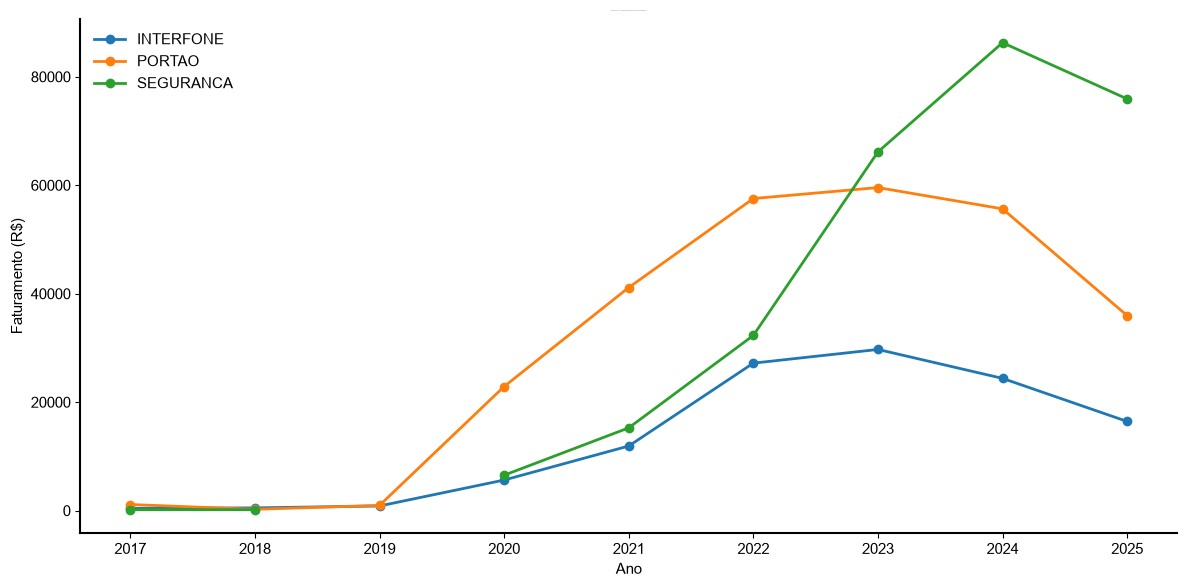

In [17]:
# INTERFONE, PORTAO e SEGURANCA
plot_faturamento_anual(
    banco,
    ["INTERFONE", "PORTAO", "SEGURANCA"],
    "Faturamento anual: INTERFONE, PORTAO e SEGURANCA"
)

#### Série de Faturamento Anual: ANTENA, COMPONENTES ANTENA e CABO

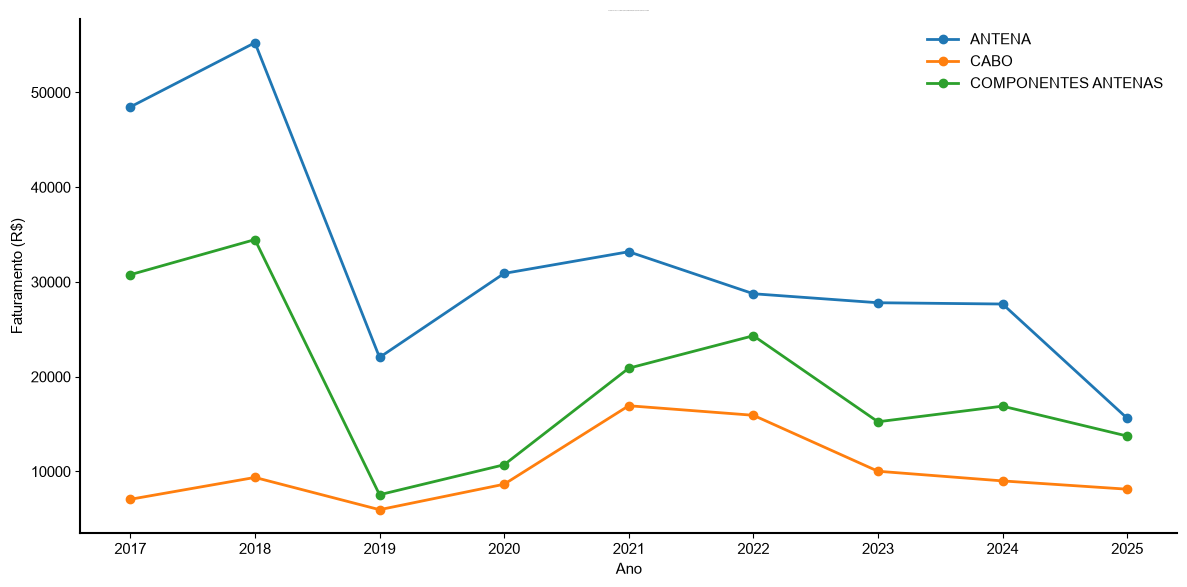

In [18]:
plot_faturamento_anual(
    banco,
    ["ANTENA", "COMPONENTES ANTENAS", "CABO"],
    "Faturamento anual: ANTENA, COMPONENTES ANTENAS e CABO"
)

Esta análise permite entender mais o negócio desta pequena empresa:
1) Nos ano iniciais, o principal foco da empresa era instalações de antenas, com foco em venda de produtos voltadas à televisões num geral; entretanto, as vendas de itens do setor de segurança começaram a crescer em 2019, ganhando um aumento expressivo em 2020 e crescendo até o ano de 2024.

2) A queda brusca no ano de 2025 foi relatado pela empresa por ser um ano com mudanças estruturais do banco de dados da empresa e, por isso, deve-se analisar com cuidado este período das séries temporais.

## Faturamento mensal total

Após as análises realizadas, entende-se que as séries temporais de número de vendas -- que se relaciona à demanda de estoque da empresa -- não serão aplicadas neste projeto, pois há uma alta variabilidade de produtos dentro de setores específicos, e com baixo número de registro por produtos. Portanto, esta característica dificultaria uma análise mais detalhada e a construção de modelos preditivos.

Também notou-se que a análise do faturamento anual é relevante para o entendimento do negócio, principalmente notando-se diferenças no número de venda em conjunto com o faturamento para diferentes setores do grupo; entretanto, não há registros suficientes de forma que a série anual seja relevante para a construção de modelos preditivos. 

**De maneira geral, encontrar modelos de predição para grupos específicos continua sendo uma grande oportunidade de estudo e ficará em aberto para futuros projetos.**

### Conclusão

A variável resposta (*target*) do modelo será o faturamento mensal total da empresa, isto é, será somado todo o faturamento no mês de cada ano separadamente, de maneira a conseguir construir um modelo que realize a predição do valor do faturamento dos anos meses futuros.

A escolha dessa variável resposta também ajudará a encontrar padrões de tendência e sazonalidade mensais, garantindo também uma nova oportunidade de realizar buscas mais detalhadas de sazonalidade por grupos específicos.

C:\Users\Marino\AppData\Local\Temp\ipykernel_52256\572128235.py:41: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title=None, frameon=False)


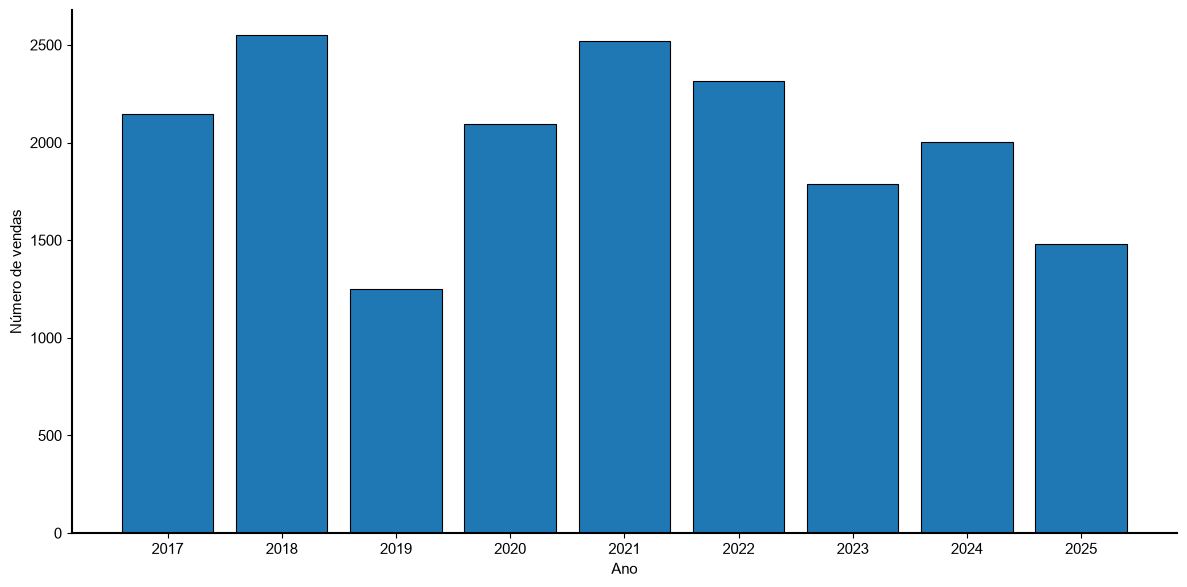

In [19]:
# 1) Agregar número de vendas por ano (uso da função utilitária)
vendas_por_ano = build_annual_counts(banco, start_year=2017, end_year=2025)

# 2) Plot (bar) usando a função de estilo
plot_with_style(
    vendas_por_ano,
    kind='bar',
    x_label='Ano',
    y_label='Número de vendas',
    xticks=list(range(2017,2026)),
    xtlabels=list(range(2017,2026))
)

C:\Users\Marino\AppData\Local\Temp\ipykernel_52256\572128235.py:41: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title=None, frameon=False)


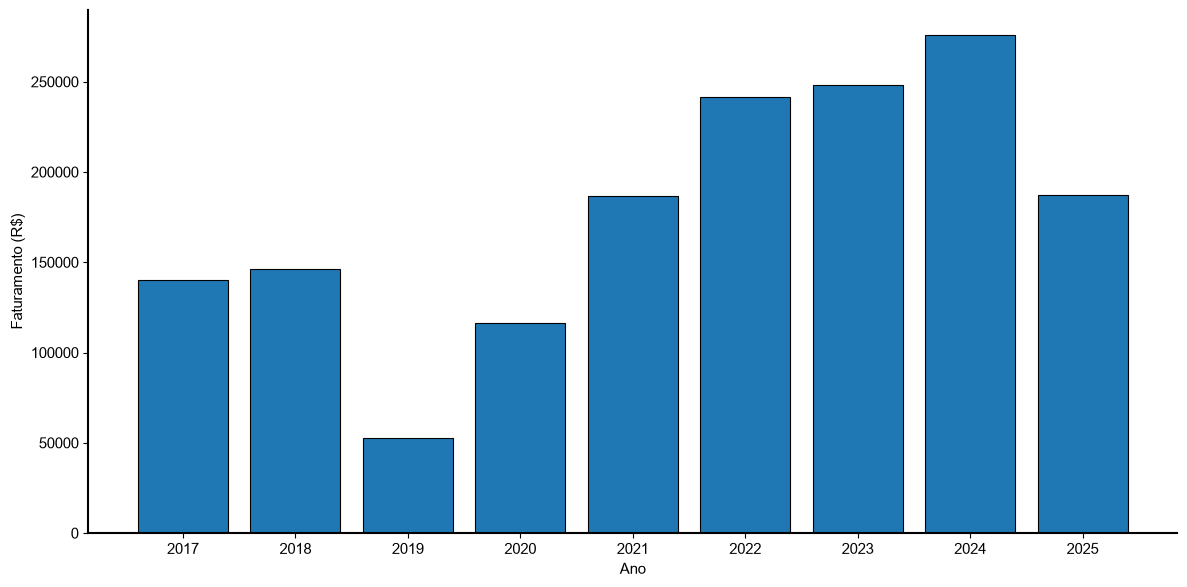

In [20]:
# faturamento anual total por ano (uso da função utilitária)
faturamento_ano = build_annual_faturamento_total(banco, start_year=2017, end_year=2025)

# Plot faturamento anual
plot_with_style(
    faturamento_ano,
    kind='bar',
    x_label='Ano',
    y_label='Faturamento (R$)',
    xticks=list(range(2017,2026)),
    xtlabels=list(range(2017,2026))
)

* O faturamento por ano complementa as informações contidas na quantidade de vendas por ano:
    1) Apesar do número de vendas de 2017 ser menor que 2018, ainda assim esses anos possuem faturamentos próximos.
    2) O faturamento do ano de 2019 foi o pior, reflexo do menor número de vendas.
    3) Houve um comportamento crescente no faturamento da empresa a partir do ano de 2019, sendo inicialmente menor em 2020, resultado esperado devido à pandemia.
    4) Por fim, a queda no faturamento em 2025 é esperado devido à falta de 4 meses de registros (9, 10, 11 e 12).

C:\Users\Marino\AppData\Local\Temp\ipykernel_52256\572128235.py:41: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title=None, frameon=False)


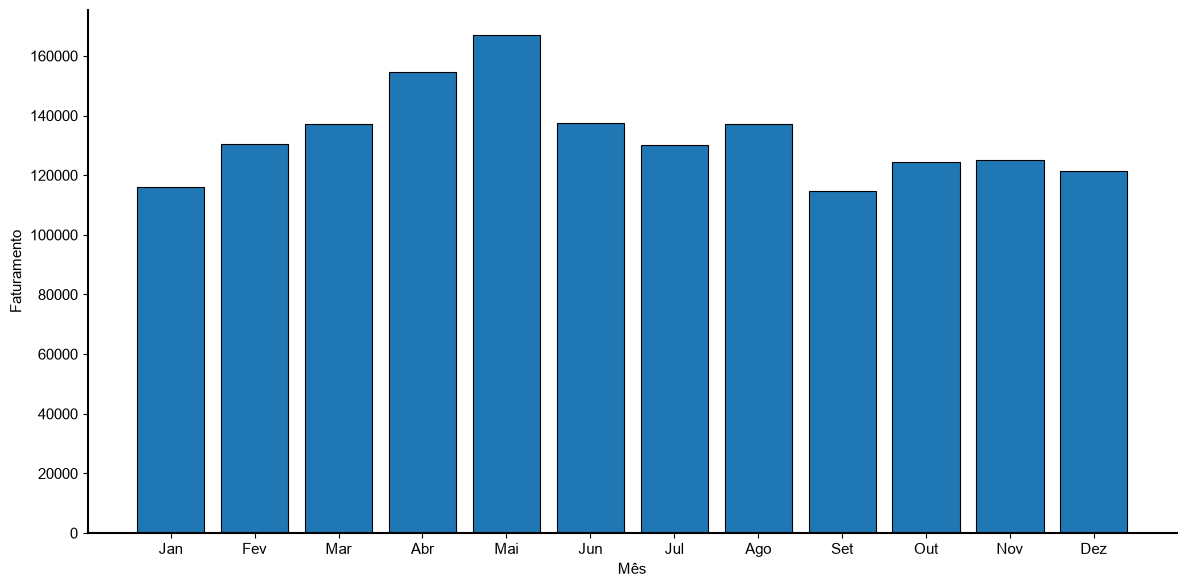

In [21]:
faturamento_mes = banco.groupby(banco['data_venda'].dt.month)['valor_total'].sum()
plot_with_style(
    faturamento_mes,
    kind='bar',
    x_label='Mês',
    y_label='Faturamento',
    xticks=list(range(1,13)),
    xtlabels=["Jan","Fev","Mar","Abr","Mai","Jun","Jul","Ago","Set","Out","Nov","Dez"]
)

In [22]:
fat_mes_ano = (
    banco
    .assign(
        ano=banco['data_venda'].dt.year,
        mes=banco['data_venda'].dt.month
    )
    .groupby(['ano','mes'])['valor_total']
    .sum()
    .reset_index() # .reset_index() é usado para transformar o índice do resultado 
    # do groupby em colunas regulares
)

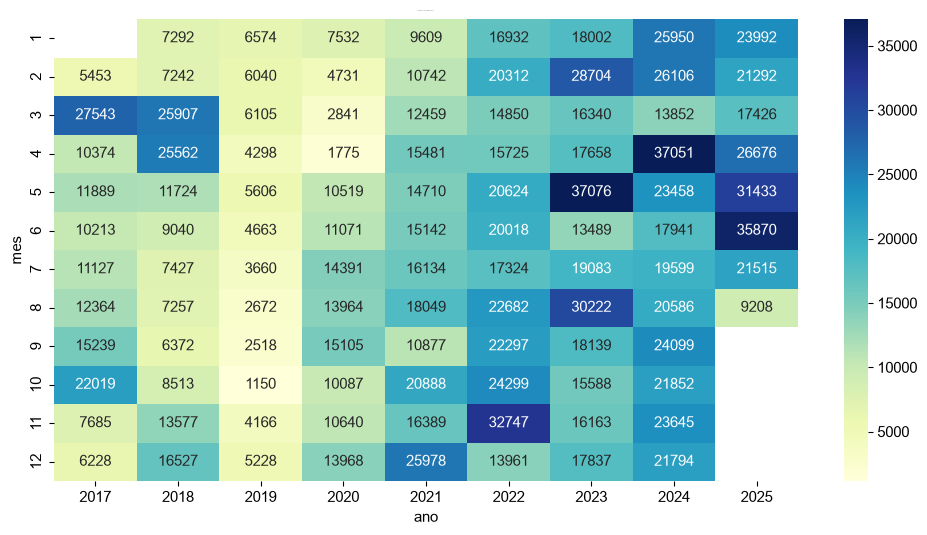

In [23]:
pivot_fat = fat_mes_ano.pivot(
    index='mes',
    columns='ano',
    values='valor_total'
)

plt.figure(figsize=(12,6))
sns.heatmap(
    pivot_fat,
    annot=True,
    fmt='.0f',
    cmap='YlGnBu'
)

plt.title('Faturamento por Mês e Ano')
plt.show()

O faturamento mensal ao longo dos anos traz análises interessantes:
1) A tendência do começo dos anos nesta empresa é de crescente, com forte pico nos meses de Abril e Maio. Isso mostra uma tendência de crescimento nos meses iniciais dos anos.
2) Em seguida, após o mês de Maio, observa-se um decrescimento nas vendas nos meses seguintes, mas com um relativo equilíbrio nas vendas após o mês de Agosto.

Essas características são reflexo das sazonalidades de férias no Brasil, início, meio e fim de ano. Analisar a série temporal mensal de faturamento ao longo dos anos torna-se imprescindível para entender a sazonalidade do faturamento. 

A partir dos resultados obtidos através do faturamento anual e mensal da empresa, pode-se perceber que:
1) sazonalidade dentro de um único ano: há tendência de crescimento e decrescimento ao longo dos anos; além de existir a sazonalidade refletida nos meses.
2) sazonalidade mensal em relação aos anos: há tendência de crescimento ao longo dos primeiros meses do ano, mas também há uma tendência de crescimento ao longo dos anos, resultado esperado para uma empresa em crescimento.

## Série Temporal Mensal do Faturamento ao longo dos anos

* Faturamento mensal ao longo dos anos -> Série Temporal
    1) Existe tendência?
    2) Existe sazonalidade?
    3) Existe ruído?

C:\Users\Marino\AppData\Local\Temp\ipykernel_52256\572128235.py:41: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title=None, frameon=False)


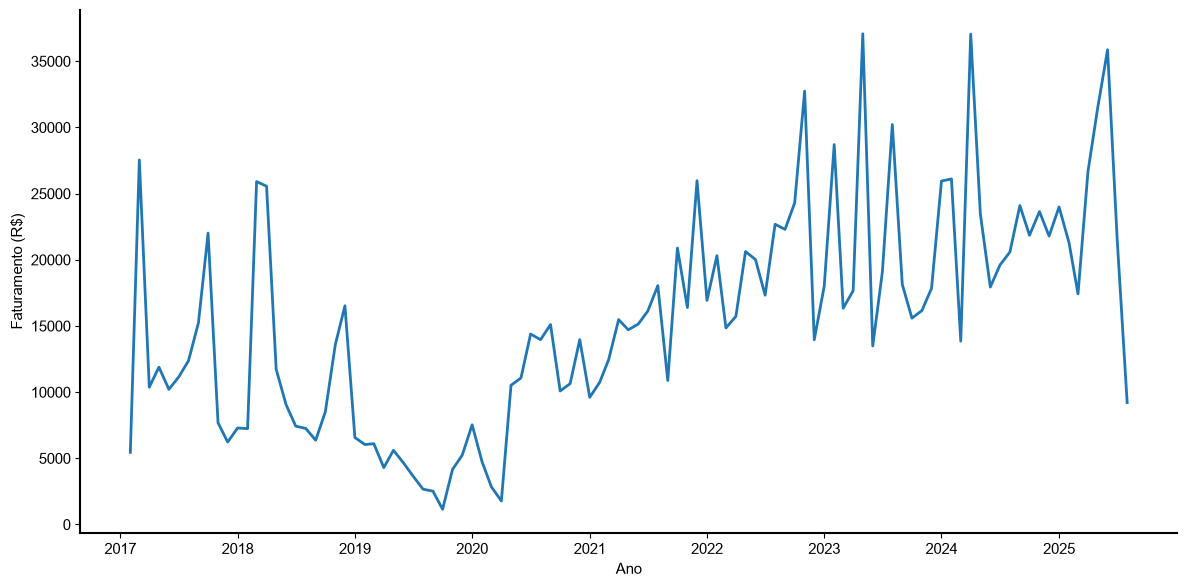

In [24]:
faturamento_mensal = build_monthly_faturamento_total(banco, start='2017-02-01', end='2025-08-01')['valor_total']

plot_with_style(
    faturamento_mensal,
    kind='line',
    x_label='Ano',
    y_label='Faturamento (R$)',
    xticks=pd.date_range('2017-01-01','2025-01-01',freq='YS'),
    xtlabels=[d.year for d in pd.date_range('2017-01-01','2025-01-01',freq='YS')],
    marker=''
)

### Existe sazonalidade após remover a tendência?

In [25]:
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.dates as mdates

#### Decomposição Aditiva

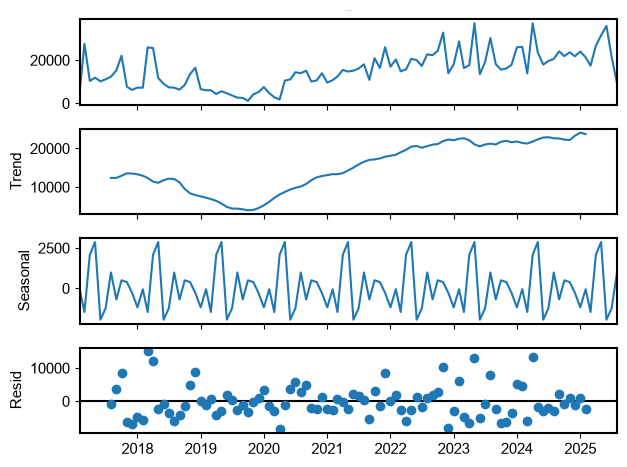

In [26]:
decomp_add = seasonal_decompose(
    faturamento_mensal,
    model='additive',
    period=12
)

decomp_add.plot();

In [29]:
def plot_decomposition(series, decomposition,
                       title='Decomposição Aditiva do Faturamento Mensal',
                       start='2017-01-01', end='2025-01-01',
                       figsize=(12,9), grid_alpha=0.3):
    import matplotlib.dates as mdates
    fig, axes = plt.subplots(4, 1, figsize=figsize, sharex=True)

    axes[0].plot(series.index, series.values, linewidth=2)
    axes[0].set_ylabel('Faturamento Mensal')

    axes[1].plot(decomposition.trend.index, decomposition.trend.values, linewidth=2)
    axes[1].set_ylabel('Tendência')

    axes[2].plot(decomposition.seasonal.index, decomposition.seasonal.values, linewidth=2)
    axes[2].set_ylabel('Sazonal')

    axes[3].plot(decomposition.resid.index, decomposition.resid.values, linewidth=2)
    axes[3].set_ylabel('Residuo')

    for ax in axes:
        ax.grid(True, alpha=grid_alpha)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
        ax.spines['left'].set_color('black')
        ax.spines['bottom'].set_color('black')
        ax.legend([], frameon=False)

    years = pd.date_range(start, end, freq='YS')
    axes[-1].xaxis.set_major_locator(mdates.YearLocator())
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    axes[-1].set_xticks(years)
    axes[-1].set_xticklabels([d.year for d in years])
    #plt.suptitle(title, fontsize=16, fontweight='bold')
    plt.tight_layout(rect=[0,0,1,0.96])
    plt.show()
    return fig, axes


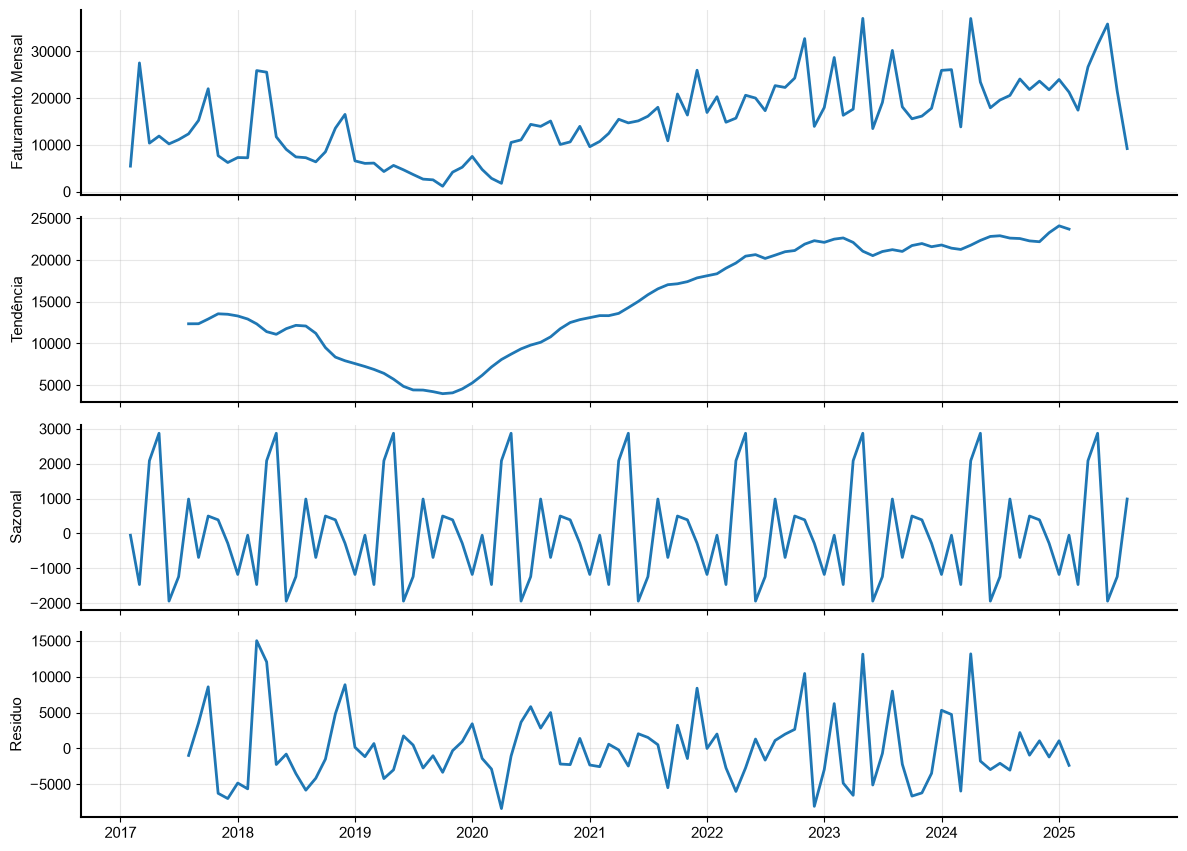

(<Figure size 1200x900 with 4 Axes>,
 array([<Axes: ylabel='Faturamento Mensal'>, <Axes: ylabel='Tendência'>,
        <Axes: ylabel='Sazonal'>, <Axes: ylabel='Residuo'>], dtype=object))

In [30]:
plot_decomposition(faturamento_mensal, decomp_add)

#### Decomposição Multiplicativa

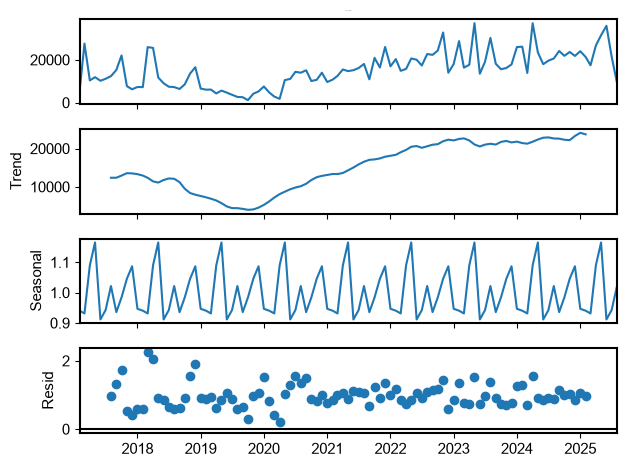

In [33]:
decomp_mul = seasonal_decompose(
    faturamento_mensal,
    model='multiplicative',
    period=12
)

decomp_mul.plot();

In [34]:
def plot_decomposition(series, decomposition,
                       title='Decomposição Multiplicativa do Faturamento Mensal',
                       start='2017-01-01', end='2025-01-01',
                       figsize=(12,9), grid_alpha=0.3):
    import matplotlib.dates as mdates
    fig, axes = plt.subplots(4, 1, figsize=figsize, sharex=True)

    axes[0].plot(series.index, series.values, linewidth=2)
    axes[0].set_ylabel('Faturamento Mensal')

    axes[1].plot(decomposition.trend.index, decomposition.trend.values, linewidth=2)
    axes[1].set_ylabel('Tendência')

    axes[2].plot(decomposition.seasonal.index, decomposition.seasonal.values, linewidth=2)
    axes[2].set_ylabel('Sazonal')

    axes[3].plot(decomposition.resid.index, decomposition.resid.values, linewidth=2)
    axes[3].set_ylabel('Residuo')

    for ax in axes:
        ax.grid(True, alpha=grid_alpha)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
        ax.spines['left'].set_color('black')
        ax.spines['bottom'].set_color('black')
        ax.legend([], frameon=False)

    years = pd.date_range(start, end, freq='YS')
    axes[-1].xaxis.set_major_locator(mdates.YearLocator())
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    axes[-1].set_xticks(years)
    axes[-1].set_xticklabels([d.year for d in years])
    #plt.suptitle(title, fontsize=16, fontweight='bold')
    plt.tight_layout(rect=[0,0,1,0.96])
    plt.show()
    return fig, axes


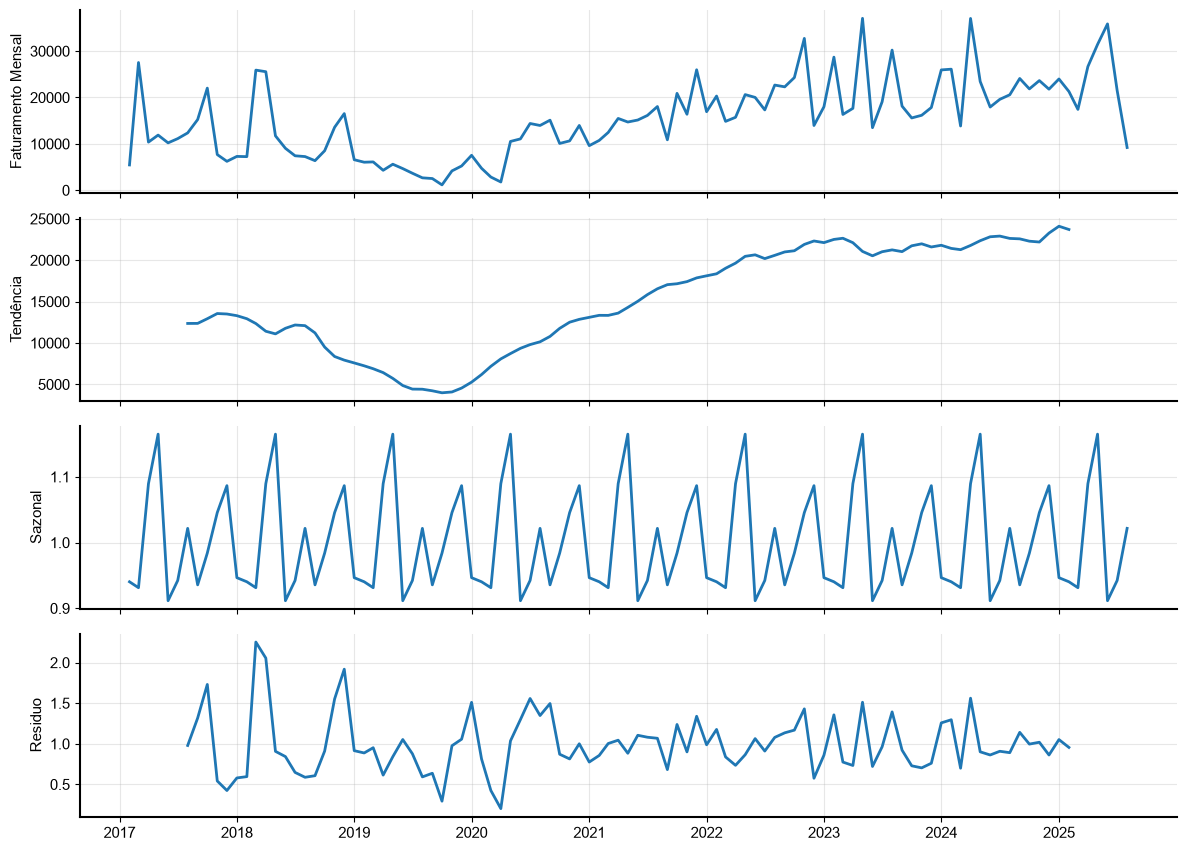

(<Figure size 1200x900 with 4 Axes>,
 array([<Axes: ylabel='Faturamento Mensal'>, <Axes: ylabel='Tendência'>,
        <Axes: ylabel='Sazonal'>, <Axes: ylabel='Residuo'>], dtype=object))

In [35]:
plot_decomposition(faturamento_mensal, decomp_mul)

## Conclusão

A análise das decomposições aditiva e multiplicativa da série temporal de faturamento mensal ao longo dos anos mostra:

1) que há tendência ao longo dos anos; inicialmente, a empresa teve uma tendência de decrescimento entre 2017 e 2020, onde o faturamento teve uma redução expressiva de R$14.500 para R$ 5000, aproximadamente. Em seguda, com o início do ano de 2020, percebe-se um crescimento lento, indícios do início da pandemia, mas com tendência de crescimento até os últimos registros de 2025.

2) Esse comportamento de tendência após a pandemia sugere uma conexão com o setor de segurança (SEGURANCA, PORTAO, INTERFONE), que apresentou crescimento no mesmo intervalo de tempo.

3) Há presença de sazonalidade ao longo dos meses do ano, sempre apresentando um pico nos meses de Abril e Maio, esse pico é nítido em ambas as decomposições. Entretanto, não foi possível concluir qual das duas decomposições é a mais indicada para construir o modelo de predição final, sendo necessário, portanto, mais testes.